# Descriptive Statistics and EDA: MonthlyRelease.xlsx

This notebook explores monthly South African banking statistics in the **Monthly Release** worksheet. The figures are in R millions. Some measures are not available for every month, so calculations use each measure's available values. Correlation shows association, not cause and effect.

In [19]:
# Load the Excel sheet and convert its figures to numbers.
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_excel("MonthlyRelease.xlsx", sheet_name="Monthly Release", header=1)
data = data.replace(r"^\s*$", pd.NA, regex=True)
data["Month"] = pd.to_datetime(data["Date"], format="%b, %Y")

# Remove thousands separators, then convert the banking measures to numeric values.
number_columns = data.columns.drop(["Date", "Month"])
data[number_columns] = data[number_columns].apply(
    lambda column: pd.to_numeric(
        column.str.replace(",", "", regex=False), errors="coerce"
    )
)

# Use key measures for the analysis.
key_columns = [
    "Total assets",
    "Total liabilities to the public",
    "Total loans and advances",
    "Cash reserve balances with the Reserve Bank",
]
data = data.sort_values("Month").reset_index(drop=True)
display(data[["Date"] + key_columns].head())

,Date,Total assets,Total liabilities to the public,Total loans and advances,Cash reserve balances with the Reserve Bank
0,"Jan, 1964",NaN,NaN,NaN,134
1,"Feb, 1964",NaN,NaN,NaN,128
2,"Mar, 1964",NaN,NaN,NaN,128
3,"Apr, 1964",NaN,NaN,NaN,132
4,"May, 1964",NaN,NaN,NaN,133


## Data quality and correlation

Missing values are expected because some measures were introduced later. The correlation table compares the selected numeric measures using the months available for each pair. Long-term growth can make correlations look strong, and correlation does not prove causation.

In [20]:
# Check missing values and duplicate rows.
print("Missing values in key measures:\n", data[key_columns].isna().sum())
print("Duplicate rows:", data.duplicated().sum())

# Show correlations between the key measures.
display(data[key_columns].corr().round(2))

Missing values in key measures:
 Total assets                                   311
Total liabilities to the public                 14
Total loans and advances                        14
Cash reserve balances with the Reserve Bank      0
dtype: int64
Duplicate rows: 0


,Total assets,Total liabilities to the public,Total loans and advances,Cash reserve balances with the Reserve Bank
Total assets,1.00,1.00,0.57,1.0
Total liabilities to the public,1.00,1.00,0.72,1.0
Total loans and advances,0.57,0.72,1.00,0.7
Cash reserve balances with the Reserve Bank,1.00,1.00,0.70,1.0


## Mean, median, standard deviation, and range

The table gives descriptive statistics for each key measure. `Count` shows how many monthly values were available.

In [21]:
# Calculate the main descriptive statistics for each key measure.
summary = data[key_columns].describe().T
summary["median"] = data[key_columns].median()
summary["range"] = summary["max"] - summary["min"]
display(summary[["count", "mean", "median", "std", "min", "max", "range"]].round(2))

,count,mean,median,std,min,max,range
Total assets,441.0,3106570.21,2821026.0,2641247.45,114781.0,9252348.0,9137567.0
Total liabilities to the public,738.0,1570633.08,351792.0,2142734.53,4820.0,8080200.0,8075380.0
Total loans and advances,738.0,13432.80,10151.0,12413.73,298.0,46728.0,46430.0
Cash reserve balances with the Reserve Bank,752.0,32558.93,3938.0,48684.44,96.0,185964.0,185868.0


## Outlier check

The 1.5 × IQR rule checks each measure separately. Values outside the fences are **potential** outliers; because these are long-term monthly series, they may reflect changes over time rather than errors.

In [22]:
# Show the IQR fences, observed range, and number of potential outliers.
outlier_rows = []
for column in key_columns:
    values = data[column].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((values < lower) | (values > upper)).sum()
    outlier_rows.append({
        "Measure": column,
        "Lower fence": lower,
        "Upper fence": upper,
        "Minimum": values.min(),
        "Maximum": values.max(),
        "Potential outliers": count,
    })

display(pd.DataFrame(outlier_rows).set_index("Measure").round(2))

,Lower fence,Upper fence,Minimum,Maximum,Potential outliers
Measure,,,,,
Total assets,-5763514.00,11370718.00,114781.0,9252348.0,0
Total liabilities to the public,-3794958.50,6412587.50,4820.0,8080200.0,39
Total loans and advances,-19297.38,38925.62,298.0,46728.0,60
Cash reserve balances with the Reserve Bank,-78977.50,132596.50,96.0,185964.0,51


## Distribution

Each histogram shows the distribution of one key measure. Blank months are excluded from that measure's plot.

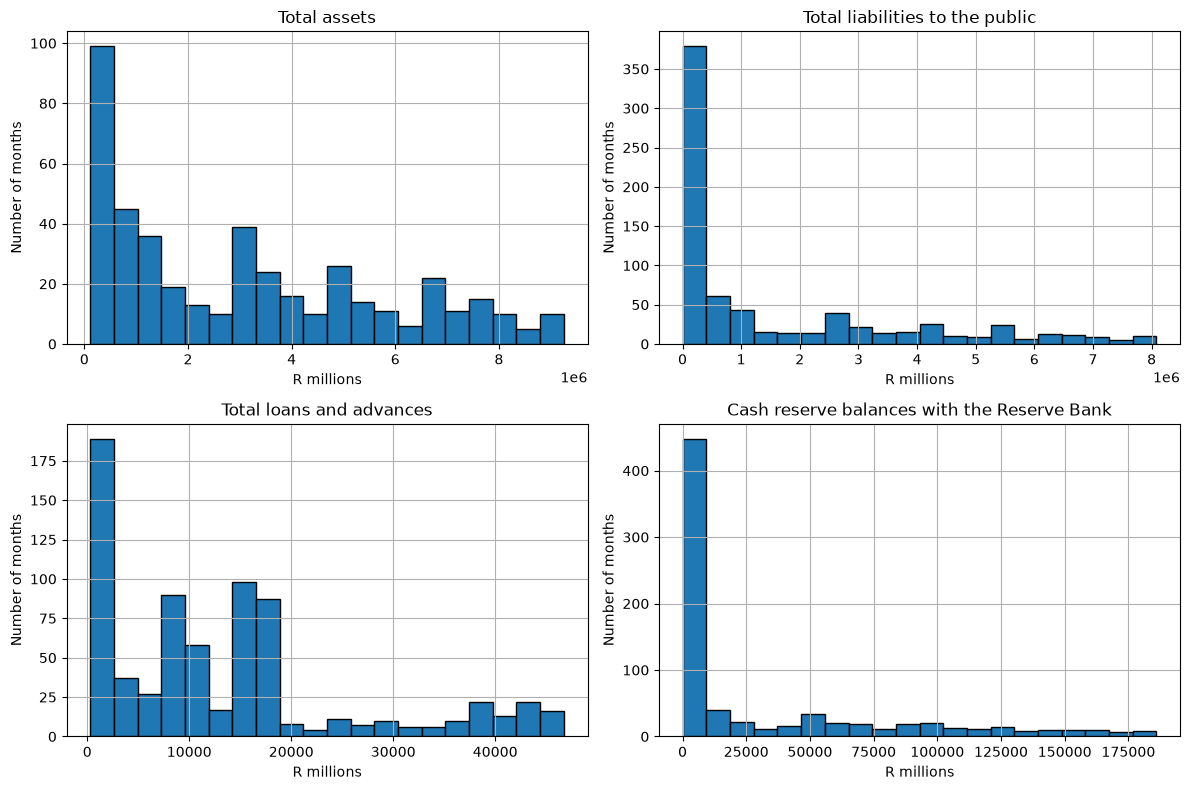

In [23]:
# Plot a separate histogram for each key measure.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for axis, column in zip(axes.flat, key_columns):
    data[column].dropna().hist(ax=axis, bins=20, edgecolor="black")
    axis.set_title(column)
    axis.set_xlabel("R millions")
    axis.set_ylabel("Number of months")
plt.tight_layout()
plt.show()

## Monthly trend and change

The trend chart and change table use **Total assets**. The table shows the latest months in the dataset, including the month-to-month amount and percentage change.

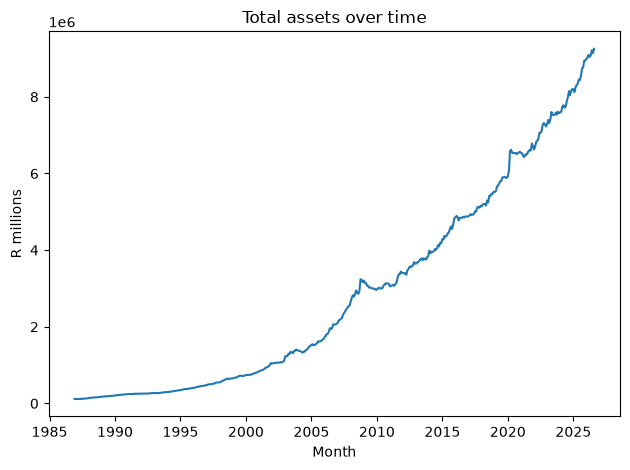

,Month,Total assets,Change,Percent change
747,2026-04-01,9043317.0,-51021.0,-0.561019
748,2026-05-01,9079609.0,36292.0,0.401313
749,2026-06-01,9216802.0,137193.0,1.511001
750,2026-07-01,9137546.0,-79256.0,-0.859908
751,2026-08-01,9252348.0,114802.0,1.256377


In [24]:
# Plot total assets over time.
assets = data[["Month", "Total assets"]].dropna().copy()
plt.plot(assets["Month"], assets["Total assets"])
plt.title("Total assets over time")
plt.xlabel("Month")
plt.ylabel("R millions")
plt.tight_layout()
plt.show()

# Calculate monthly changes in total assets.
assets["Change"] = assets["Total assets"].diff()
assets["Percent change"] = assets["Total assets"].pct_change() * 100
display(assets.tail())